# 04 Analysis

SQL analysis of NYC restaurant inspections, answering:
- **Q1:** Do inspection scores bunch just below the A-grade threshold (13 points)?
- **Q2:** Does a restaurant's grade predict the outcome of its next inspection?
- **Q3:** Are violations concentrated in a small share of restaurants and violation types?

In [1]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 7.8 MB 10.8 MB/s eta 0:00:01
     |████████████████████████████████| 126 kB 20.6 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 16.0 MB/s eta 0:00:01
     |████████████████████████████████| 4.7 MB 42.3 MB/s eta 0:00:01
     |████████████████████████████████| 249 kB 24.8 MB/s eta 0:00:01
     |████████████████████████████████| 2.9 MB 42.7 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


### connect data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

engine = create_engine("postgresql+psycopg2://localhost:5433/nyc_restaurants")

def q(sql):
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

Matplotlib is building the font cache; this may take a moment.


## Q1: Score bunching at the A-grade threshold

An initial inspection scoring 0–13 earns an A immediately; 14 or more triggers a re-inspection. If restaurants or inspectors respond to this threshold, we would expect unusually many scores at 13 and unusually few at 14.

In [2]:
dist = q("""
SELECT score, COUNT(*) AS n
FROM inspections
WHERE in_scope
  AND inspection_stage = 'Initial Inspection'
  AND score IS NOT NULL
GROUP BY score
ORDER BY score;
""")

print("total initial inspections:", dist["n"].sum())
dist.head(20)

total initial inspections: 56872


,score,n
0,0,489
1,2,1963
2,3,726
3,4,1104
4,5,2026
5,6,595
6,7,3029
7,8,1516
8,9,2803
9,10,3758


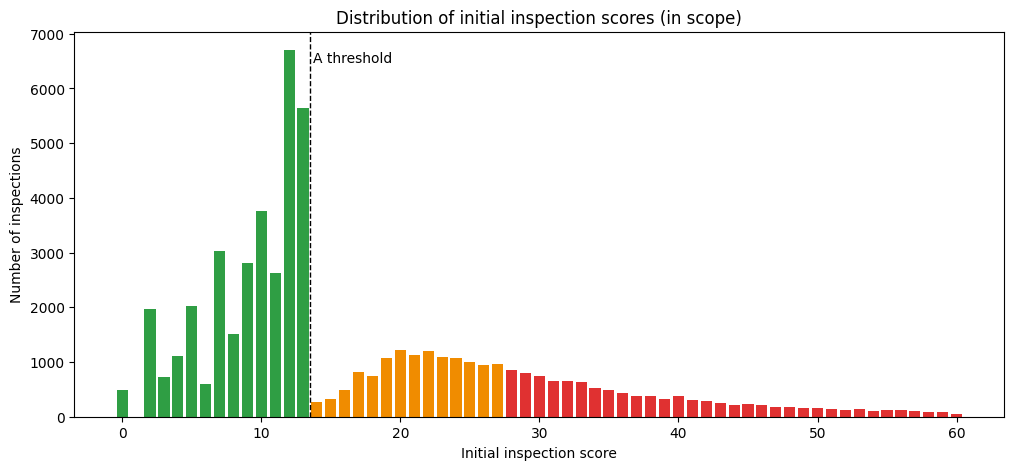

In [8]:
def band_color(score):
    """Color by grade band: A (0-13), B (14-27), C (28+)."""
    if score <= 13:
        return "#2f9e44"
    if score <= 27:
        return "#f08c00"
    return "#e03131"

plot_df = dist[dist["score"] <= 60]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(plot_df["score"], plot_df["n"], color=[band_color(s) for s in plot_df["score"]])
ax.axvline(13.5, color="black", linestyle="--", linewidth=1)
ax.text(13.7, ax.get_ylim()[1] * 0.92, "A threshold", fontsize=10)

ax.set_xlabel("Initial inspection score")
ax.set_ylabel("Number of inspections")
ax.set_title("Distribution of initial inspection scores (in scope)")
plt.savefig("../figures/q1_initial_score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
zoom = dist[dist["score"].between(9, 18)].copy()
zoom["pct_of_all"] = (zoom["n"] / dist["n"].sum() * 100).round(2)
zoom

,score,n,pct_of_all
8,9,2803,4.93
9,10,3758,6.61
10,11,2618,4.60
11,12,6702,11.78
12,13,5642,9.92
13,14,261,0.46
14,15,319,0.56
15,16,483,0.85
16,17,812,1.43
17,18,737,1.30


In [5]:
ratio = dist[dist["score"] <= 40].copy()
ratio["next_n"] = ratio["n"].shift(-1)
ratio["ratio_to_next"] = (ratio["n"] / ratio["next_n"]).round(2)

ratio.sort_values("ratio_to_next", ascending=False).head(8)

,score,n,next_n,ratio_to_next
12,13,5642,261.0,21.62
4,5,2026,595.0,3.41
1,2,1963,726.0,2.70
6,7,3029,1516.0,2.00
9,10,3758,2618.0,1.44
32,33,642,533.0,1.20
11,12,6702,5642.0,1.19
37,38,370,316.0,1.17


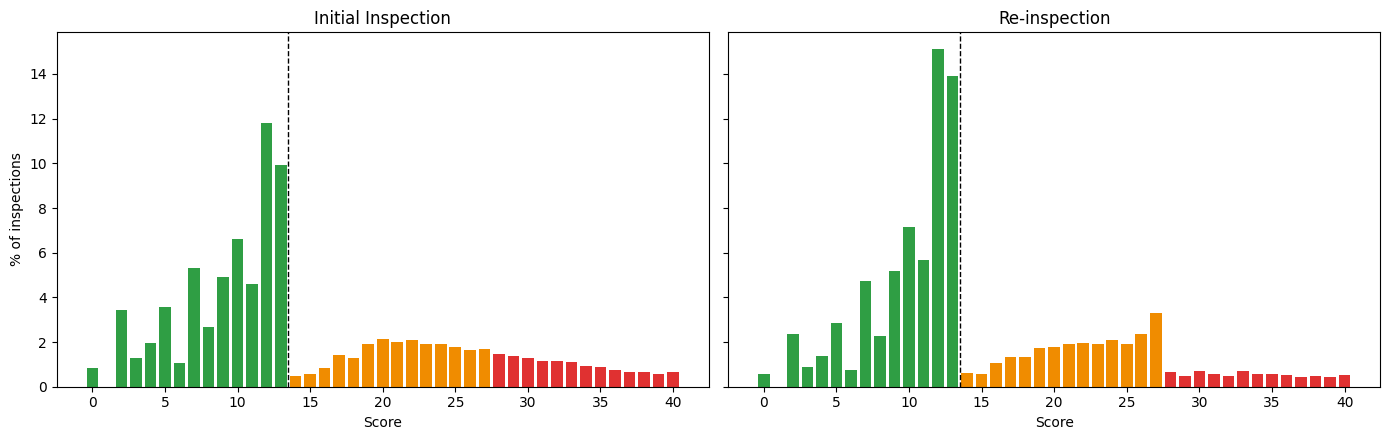

In [10]:
by_stage = q("""
SELECT inspection_stage, score, COUNT(*) AS n
FROM inspections
WHERE in_scope
  AND score IS NOT NULL
GROUP BY inspection_stage, score
ORDER BY inspection_stage, score;
""")

# Percentages use ALL scores as the denominator
by_stage["pct"] = by_stage["n"] / by_stage.groupby("inspection_stage")["n"].transform("sum") * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, stage in zip(axes, ["Initial Inspection", "Re-inspection"]):
    # Filter to 0-40 for display only
    d = by_stage[(by_stage["inspection_stage"] == stage) & (by_stage["score"] <= 40)]
    ax.bar(d["score"], d["pct"], color=[band_color(s) for s in d["score"]])
    ax.axvline(13.5, color="black", linestyle="--", linewidth=1)
    ax.set_title(stage)
    ax.set_xlabel("Score")
axes[0].set_ylabel("% of inspections")
plt.tight_layout()
plt.savefig("../figures/q1_initial_vs_reinspection.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Compare the B/C threshold (27 vs 28) across stages
threshold_check = by_stage[by_stage["score"].isin([26, 27, 28, 29])].pivot(
    index="score", columns="inspection_stage", values="pct"
).round(2)
threshold_check

inspection_stage,Initial Inspection,Re-inspection
score,,
26,1.65,2.34
27,1.69,3.30
28,1.49,0.64
29,1.39,0.47


### Q1 Findings

- **Strong bunching at the A threshold.** Scores of 12 and 13 account for 21.7% of all initial inspections, while 14 accounts for only 0.46%. The drop from 13 to 14 (21.6x) is more than six times larger than any other adjacent-score drop (next largest: 3.4x).
- **Bunching is stronger when stakes are higher.** In re-inspections, which determine the posted grade, scores of 12–13 make up about 31% of inspections, versus about 24% in initial inspections.